# 01 — Data Preprocessing
**Project:** GameGuard AI · **Task:** Binary gaming-chat toxicity detection

**Goal:** Understand the raw GameTox messages and produce trustworthy train, validation, and test datasets. This notebook does **not** train a model.

- `0` = Not Toxic (original label `0`)
- `1` = Toxic (original labels `1–5`)

**Input:** `data/raw/gametox/train.csv` · **Output:** three CSV files in `data/processed/`.

## 1. Setup and load data
Run this notebook from either the repository root or `notebooks/`. Keep the downloaded raw data unchanged.

In [10]:
from pathlib import Path
import html
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

ROOT = next(
    (
        folder for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "raw" / "gametox" / "train.csv").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/gametox/train.csv"
    )

# Define dataset paths
RAW_PATH = ROOT / "data" / "raw" / "gametox" / "train.csv"
OUTPUT_DIR = ROOT / "data" / "processed"

# Load dataset
raw = pd.read_csv(RAW_PATH, encoding="utf-8-sig")

## 2. Understand the labels and data quality
The source dataset has six labels. We are building a **binary** classifier, so label `0` stays Not Toxic and labels `1–5` become Toxic. Inspect the original counts *before* changing them.

In [11]:
print("Missing values:")
print(raw[["message", "label"]].isna().sum().to_string())
print("\nOriginal label distribution:")
print(raw["label"].value_counts(dropna=False).sort_index().to_string())
print(f"\nRepeated exact messages: {raw['message'].duplicated().sum():,}")

Missing values:
message    0
label      0

Original label distribution:
label
0.0    34797
1.0     5925
2.0     1874
3.0      279
4.0       60
5.0       24

Repeated exact messages: 14,729


In [12]:
# Fail visibly if the source uses unexpected or missing label values.
numeric_labels = pd.to_numeric(raw["label"], errors="coerce")
if numeric_labels.isna().any() or not numeric_labels.isin(range(6)).all():
    raise ValueError("Expected only the original numeric labels 0, 1, 2, 3, 4, 5.")

df = raw[["message"]].copy()
df["label"] = (numeric_labels != 0).astype("int8")
df = df.dropna(subset=["message"]).copy()
print(df["label"].value_counts().rename(index={0: "Not Toxic", 1: "Toxic"}))

label
Not Toxic    34797
Toxic         8162
Name: count, dtype: int64


## 3. Clean the text without removing meaning
Normalize whitespace, HTML entities, and Unicode. **Keep** punctuation, emoji, profanity, capital letters, and other languages: those can carry important meaning. Do not remove stopwords or stem words here.

In [13]:
def clean_message(value: str) -> str:
    text = html.unescape(str(value))
    text = unicodedata.normalize("NFC", text)
    text = text.replace("\u200b", "")  # zero-width space
    return re.sub(r"\s+", " ", text).strip()


before_cleaning = len(df)
df["message"] = df["message"].map(clean_message)

# '#ERROR!' is a spreadsheet/export artifact, not a chat message.
invalid = df["message"].eq("") | df["message"].str.fullmatch(
    r"#ERROR!", case=False
)
df = df.loc[~invalid].copy()
print(f"Removed {before_cleaning - len(df):,} empty/error rows")

Removed 137 empty/error rows


## 4. Handle contradictions and duplicate messages
A repeated chat message can have different labels depending on context. Since this dataset has no conversation history, we **remove messages with conflicting binary labels** instead of arbitrarily choosing one. We then keep a single example of every remaining normalized message to reduce memorization and prevent leakage across splits.

In [14]:
# A grouping key catches small capitalization differences (e.g. 'GG' vs 'gg').
df["message_key"] = df["message"].str.casefold()

label_counts_per_text = df.groupby("message_key")["label"].nunique()
conflicting_keys = set(label_counts_per_text[label_counts_per_text > 1].index)
conflicting_rows = df["message_key"].isin(conflicting_keys).sum()

df = df.loc[~df["message_key"].isin(conflicting_keys)].copy()
rows_before_dedup = len(df)
df = df.drop_duplicates(subset="message_key", keep="first").copy()
removed_duplicates = rows_before_dedup - len(df)

print(f"Conflicting messages removed: {len(conflicting_keys):,} unique texts ({conflicting_rows:,} rows)")
print(f"Consistent duplicate rows removed: {removed_duplicates:,}")
print(f"Clean, unique messages remaining: {len(df):,}")

Conflicting messages removed: 247 unique texts (5,978 rows)
Consistent duplicate rows removed: 9,421
Clean, unique messages remaining: 27,423


## 5. Inspect the cleaned class distribution
The classes do not need to be artificially balanced before splitting. In the **model-development notebook**, we can compare class weighting and other approaches using training data only.

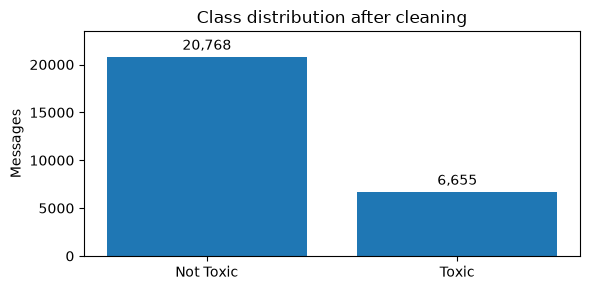

Toxic share: 24.3%


In [15]:
counts = df["label"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(["Not Toxic", "Toxic"], counts.values)
ax.bar_label(bars, labels=[f"{n:,}" for n in counts.values], padding=3)
ax.set_ylabel("Messages")
ax.set_title("Class distribution after cleaning")
ax.set_ylim(0, counts.max() * 1.13)
plt.tight_layout()
plt.show()

print(f"Toxic share: {counts.loc[1] / len(df):.1%}")

## 6. Make reproducible train / validation / test splits
Use **70% train, 15% validation, 15% test**, stratified by binary label. Because duplicates and conflicting messages were already handled, the same normalized message cannot appear in multiple splits.

- **Train:** fit the TF-IDF vectorizer and models.
- **Validation:** choose models and tune settings.
- **Test:** evaluate the final chosen pipeline once.

In [16]:
train_df, remainder_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=RANDOM_STATE,
)
val_df, test_df = train_test_split(
    remainder_df,
    test_size=0.50,
    stratify=remainder_df["label"],
    random_state=RANDOM_STATE,
)

# Verify there is no message leakage between splits.
train_keys = set(train_df["message_key"])
val_keys = set(val_df["message_key"])
test_keys = set(test_df["message_key"])
assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)
assert sum(map(len, [train_df, val_df, test_df])) == len(df)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Messages": [len(train_df), len(val_df), len(test_df)],
    "Toxic %": [f"{part['label'].mean():.1%}"
                for part in (train_df, val_df, test_df)],
})
split_summary

,Split,Messages,Toxic %
0,Train,19196,24.3%
1,Validation,4113,24.3%
2,Test,4114,24.3%


## 7. Save the data for the next notebooks
Export only the two columns needed for model training: `message` and `label`. The original CSV remains unchanged.

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for filename, part in (
    ("train.csv", train_df),
    ("validation.csv", val_df),
    ("test.csv", test_df),
):
    output_path = OUTPUT_DIR / filename
    part[["message", "label"]].to_csv(output_path, index=False, encoding="utf-8")
    print(f"Saved {output_path.relative_to(ROOT)} ({len(part):,} rows)")

assert set(train_df["label"].unique()) == {0, 1}
assert set(val_df["label"].unique()) == {0, 1}
assert set(test_df["label"].unique()) == {0, 1}
print("\nChecks passed: valid binary labels and no overlapping messages.")

Saved data\processed\train.csv (19,196 rows)
Saved data\processed\validation.csv (4,113 rows)
Saved data\processed\test.csv (4,114 rows)

Checks passed: valid binary labels and no overlapping messages.


### Next: `02_Model_Development.ipynb`
Load `data/processed/train.csv` and `validation.csv`. Fit TF-IDF **only on the training split** and apply it to validation; never fit preprocessing on the full dataset. Compare a simple baseline before attempting more complex models. Keep `test.csv` untouched until the final evaluation notebook.

**Known limitation:** These are *World of Tanks* messages, with short multilingual chat and some source-specific phrases. Strong scores here do not automatically prove the classifier generalizes to League of Legends or Valorant.